In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 300

# t_final = 1.0e-4
t_final = 1.0e-4

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.99

ion_density = 1.0e21
ion_velocity = 0
ion_temperature = 1

K_cx = 3.2e-15 * np.sqrt(ion_temperature/0.026)
collision_rate = K_cx * ion_density

BGK_stddev = np.sqrt(ion_temperature * 1.602176634e-19 / 1.67e-27)

D = BGK_stddev**2 / collision_rate


print('Collision rate: ', collision_rate)
print('Average collision time: ', 1/collision_rate)

print('Expected deviation: ', np.sqrt(2*D*t_final))
print('99.9 range: ', 2 * 2.6 * np.sqrt(2*D*t_final))
print(x)

Collision rate:  19845557.534273352
Average collision time:  5.038911092686594e-08
Expected deviation:  0.031094265820033933
99.9 range:  0.16169018226417645
[0.         0.00333333 0.00666667 0.01       0.01333333 0.01666667
 0.02       0.02333333 0.02666667 0.03       0.03333333 0.03666667
 0.04       0.04333333 0.04666667 0.05       0.05333333 0.05666667
 0.06       0.06333333 0.06666667 0.07       0.07333333 0.07666667
 0.08       0.08333333 0.08666667 0.09       0.09333333 0.09666667
 0.1        0.10333333 0.10666667 0.11       0.11333333 0.11666667
 0.12       0.12333333 0.12666667 0.13       0.13333333 0.13666667
 0.14       0.14333333 0.14666667 0.15       0.15333333 0.15666667
 0.16       0.16333333 0.16666667 0.17       0.17333333 0.17666667
 0.18       0.18333333 0.18666667 0.19       0.19333333 0.19666667
 0.2        0.20333333 0.20666667 0.21       0.21333333 0.21666667
 0.22       0.22333333 0.22666667 0.23       0.23333333 0.23666667
 0.24       0.24333333 0.24666667 0.25

In [3]:
# simulate using monte carlo

n_cells_mc = 300
n_particles = 10000
density_mc = np.zeros(n_cells_mc, dtype=float)
x_mc = np.linspace(0, 1, n_cells_mc+1)
x_center_mc = 0.5 * (x_mc[:-1] + x_mc[1:])
for i in range(n_particles):
    x_particle = x0
    t = 0
    v = np.random.normal(ion_velocity, BGK_stddev)

    while t < t_final:
        # time till next collision
        eps = np.random.rand()
        tc = -np.log(eps) / collision_rate
        tc = min(tc, t_final - t)

        # calculate time till boundary hit
        t_boundary = np.inf
        if v > 0:
            t_boundary = (1 - x_particle) / v
        elif v < 0:
            t_boundary = x_particle / -v

        if t_boundary < tc:
            # move particle to boundary
            x_particle += v * t_boundary
            v = -v
            t += t_boundary
            continue

        # move particle
        x_particle += v * tc
        # draw new velocity
        v = np.random.normal(ion_velocity, BGK_stddev)
        t += tc

    # tally final position
    x_index = int(x_particle * n_cells_mc)
    volume = 1/(n_cells_mc)
    density_mc[x_index] += 1/volume / n_particles

In [4]:
# simulate using backward euler
dt = t_final / 2
r = D * dt / h**2

# matrix A for implicit method
A = np.zeros((n_cells, n_cells)) 
A[0, 0] = 1 + r
A[0, 1] = -r
A[-1, -1] = 1 + r
A[-1, -2] = -r
for i in range(1, n_cells-1):
    A[i, i] = 1 + 2 * r
    A[i, i-1] = -r
    A[i, i+1] = -r

density_fluid = np.zeros(n_cells)

x_index = int(x0 * n_cells)
density_fluid[x_index] = n_cells

# x_index_left = math.floor(x0 * n_cells)
# x_index_right = math.ceil(x0 * n_cells)
# if x_index_left == x_index_right:
#     weight_left = 0
#     weight_right = 1
# else:
#     weight_left = x_index_right - x0 * n_cells
#     weight_right = x0 * n_cells - x_index_left

# print('x_index_left: ', x_index_left)
# print('x_index_right: ', x_index_right)
# print('weight_left: ', weight_left)
# print('weight_right: ', weight_right)

# density_fluid[x_index_left] = n_cells * weight_left
# density_fluid[x_index_right] = n_cells * weight_right

print('Initial density: ', density_fluid)

# density_fluid = np.linalg.solve(A, density_fluid)

for t in np.arange(0, t_final, dt):
    density_fluid = np.linalg.solve(A, density_fluid)

print('Final density: ', density_fluid)

Initial density:  [  0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0

In [5]:
# Analytical model

density_analytical = np.zeros(n_cells)

# calculate reflection coefficient so that flux is zero at x = 1
R = 1

for i in range(n_cells):
    x_center = (i + 0.5) / n_cells
    density_analytical[i] = np.exp( -( x_center - x0 )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final) + R * np.exp( -( x_center + x0 - 2 )**2/ (4*D*t_final) ) / np.sqrt(4*np.pi*D*t_final)

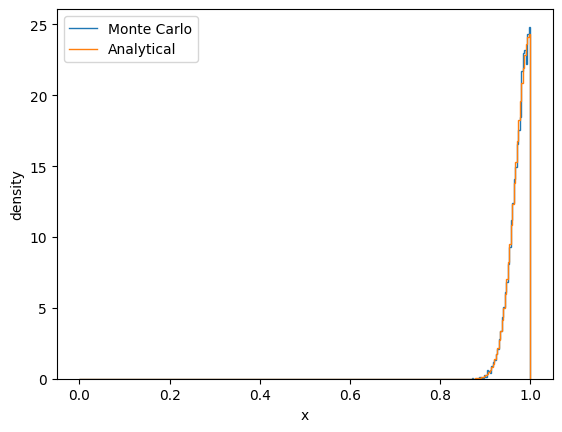

In [7]:

plt.stairs(density_mc, x_mc, label='Monte Carlo')
# plt.stairs(density_fluid, x, label='Finite Difference')
plt.stairs(density_analytical, x, label='Analytical')
plt.legend()
plt.xlabel('x')
plt.ylabel('density')
plt.show()